**CS 4140 – Deep Learning · L03 · Networks as function approximators** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L03_function-approximators/L03_networks_as_function_approximators.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L03_function-approximators"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 3 — Demo: networks as function approximators

**What to look for**

1. **Width** — more hidden units give the network more "pieces" to bend a function with.
2. **Activation** — without a nonlinearity, any number of layers collapses to a straight line.
3. **Depth** — composing layers multiplies the number of pieces.
4. **Expressive power ≠ what training finds** — a network that *can* represent XNOR does not always *learn* it.
5. **A dense image classifier** — the same recipe on Fashion-MNIST: trace one minibatch through the model.

Sections 1–5 take under a minute on a laptop CPU. Section 6 downloads Fashion-MNIST (≈30 MB) and trains for about a minute;
to skip training, set `TRAIN_IMAGES = False` and put `fashion_mlp.pt` next to the notebook.

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

SAVE_FIGS = False
TRAIN_IMAGES = True
FIG_DIR = 'figures'
if SAVE_FIGS:
    import os
    os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({'font.size': 14, 'mathtext.fontset': 'cm'})


def n_params(model):
    """Number of learnable numbers (weights and biases) in a model."""
    return sum(p.numel() for p in model.parameters())


def mlp(n_in, width, n_out, depth=1, act=nn.ReLU):
    """depth hidden layers of `width` units each, then a linear output layer."""
    layers, d = [], n_in
    for _ in range(depth):
        layers += [nn.Linear(d, width), act()]
        d = width
    layers.append(nn.Linear(d, n_out))
    return nn.Sequential(*layers)


def fit(model, x, y, loss_fn, steps=3000, lr=1e-2):
    opt = torch.optim.Adam(model.parameters(), lr=lr)   # Adam: a smarter step rule (Jan 27); same recipe
    for _ in range(steps):
        loss = loss_fn(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

## 1. Width and activation: fitting a 1-D function
Target: $f(x)=\sin(3x)+0.3x$ on $[-2,2]$. One hidden layer, different widths.
The last panel uses the identity "activation" $g(z)=z$ with 64 units: watch what happens.

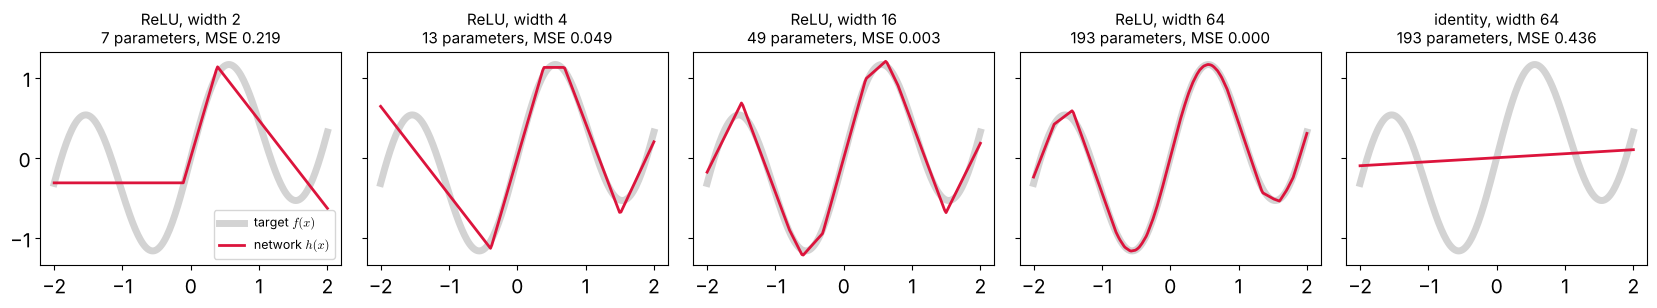

In [2]:
torch.manual_seed(0)
x1 = torch.linspace(-2, 2, 200).unsqueeze(1)
f1 = torch.sin(3 * x1) + 0.3 * x1

configs = [('ReLU', 2), ('ReLU', 4), ('ReLU', 16), ('ReLU', 64), ('identity', 64)]
fig, ax = plt.subplots(1, len(configs), figsize=(17, 3.3), sharey=True)
for a, (act_name, w) in zip(ax, configs):
    torch.manual_seed(1)
    act = nn.ReLU if act_name == 'ReLU' else nn.Identity
    net = mlp(1, w, 1, act=act)
    final = fit(net, x1, f1, nn.MSELoss(), steps=4000, lr=1e-2)
    with torch.no_grad():
        a.plot(x1, f1, color='lightgray', lw=5, label='target $f(x)$')
        a.plot(x1, net(x1), color='crimson', lw=2, label='network $h(x)$')
    a.set_title(f'{act_name}, width {w}\n{n_params(net)} parameters, MSE {final:.3f}', fontsize=11)
ax[0].legend(fontsize=9, loc='lower right')
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/width_activation_1d.png', dpi=200)
plt.show()

## 2. Why the nonlinearity matters (algebra check)
Two linear layers without an activation are one linear layer: $W_2(W_1x+b_1)+b_2=(W_2W_1)x+(W_2b_1+b_2)$.

In [3]:
torch.manual_seed(0)
lin2 = nn.Sequential(nn.Linear(3, 5), nn.Linear(5, 2))          # 3 -> 5 -> 2, no activation
W1, b1 = lin2[0].weight, lin2[0].bias
W2, b2 = lin2[1].weight, lin2[1].bias
W, b = W2 @ W1, W2 @ b1 + b2                                     # the single equivalent layer
xt = torch.randn(4, 3)
print('max difference:', (lin2(xt) - (xt @ W.T + b)).abs().max().item())

max difference: 5.960464477539063e-08


## 3. Depth: composing a "fold" doubles the number of linear pieces
The tent map $t(x)=2\,\mathrm{ReLU}(x)-4\,\mathrm{ReLU}(x-\tfrac12)$ on $[0,1]$ is a 2-unit ReLU layer.
Composing it $k$ times gives $2^k$ linear pieces with only $2k$ hidden units.

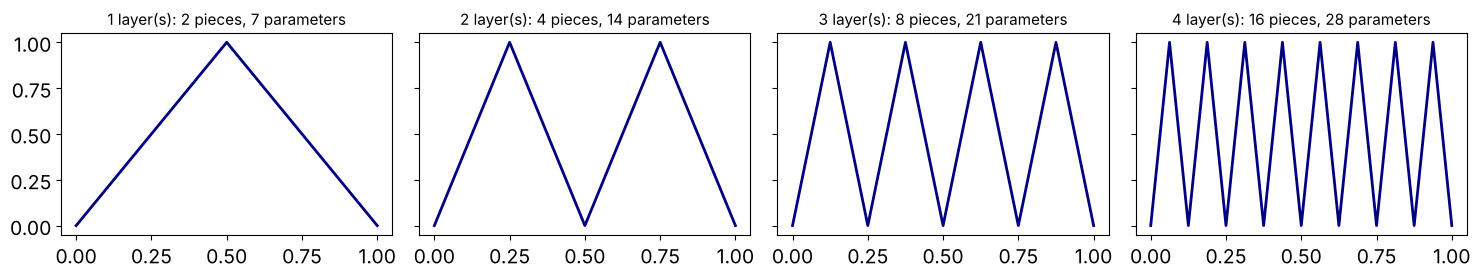

In [4]:
def tent_layer():
    layer = nn.Sequential(nn.Linear(1, 2), nn.ReLU(), nn.Linear(2, 1))
    with torch.no_grad():
        layer[0].weight.copy_(torch.tensor([[1.0], [1.0]]))
        layer[0].bias.copy_(torch.tensor([0.0, -0.5]))
        layer[2].weight.copy_(torch.tensor([[2.0, -4.0]]))
        layer[2].bias.zero_()
    return layer

xs = torch.linspace(0, 1, 2001).unsqueeze(1)
fig, ax = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for k, a in enumerate(ax, start=1):
    deep = nn.Sequential(*[tent_layer() for _ in range(k)])
    with torch.no_grad():
        a.plot(xs, deep(xs), color='navy', lw=2)
    a.set_title(f'{k} layer(s): {2 ** k} pieces, {n_params(deep)} parameters', fontsize=11)
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/depth_sawtooth.png', dpi=200)
plt.show()

## 4. Expressive power vs. what training actually learns: XNOR
In the slides we *built* a 2-2-1 network that computes XNOR, so this architecture **can** represent it.
Here we let gradient descent find the weights, starting from 20 different random initializations.

In [5]:
X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
Y = torch.tensor([[1.], [0.], [0.], [1.]])            # XNOR, as in the slides


def train_xnor(width, seed, steps=4000, lr=2.0):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(2, width), nn.Sigmoid(), nn.Linear(width, 1), nn.Sigmoid())
    opt = torch.optim.SGD(net.parameters(), lr=lr)      # plain gradient descent, as on Jan 15
    for _ in range(steps):
        loss = nn.BCELoss()(net(X), Y)
        opt.zero_grad(); loss.backward(); opt.step()
    solved = bool(((net(X) > 0.5).float() == Y).all())
    return net, solved, loss.item()


results = {}
for width in (2, 8):
    runs = [train_xnor(width, s) for s in range(20)]
    results[width] = runs
    print(f'2-{width}-1 network ({n_params(runs[0][0])} parameters): '
          f'solved XNOR in {sum(r[1] for r in runs)}/20 runs')

2-2-1 network (9 parameters): solved XNOR in 18/20 runs


2-8-1 network (33 parameters): solved XNOR in 20/20 runs


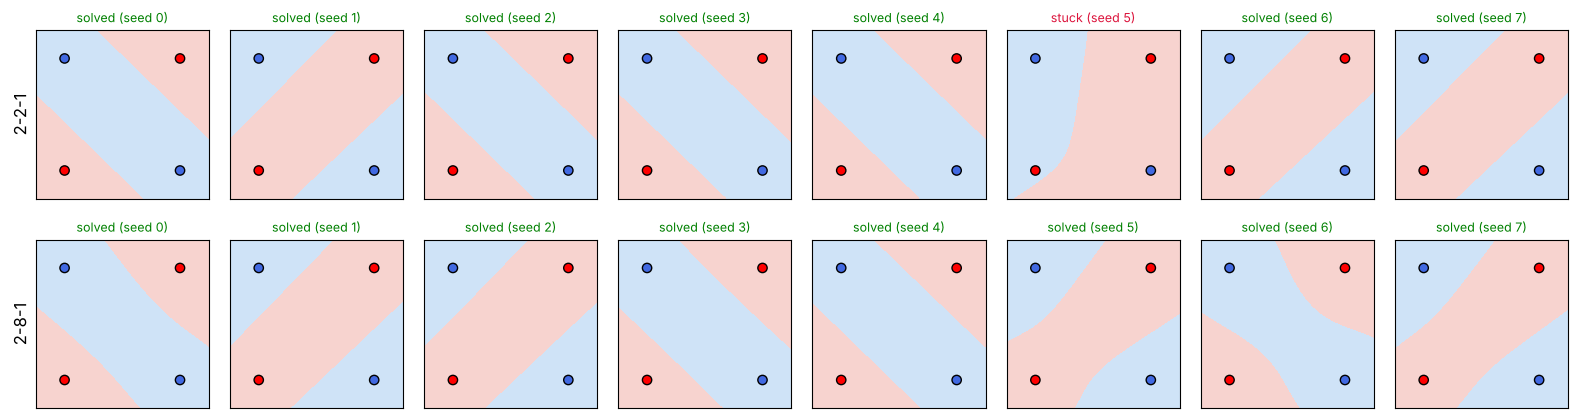

In [6]:
g = torch.linspace(-0.25, 1.25, 120)
G1, G2 = torch.meshgrid(g, g, indexing='xy')
grid = torch.stack([G1.ravel(), G2.ravel()], 1)
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for row, width in enumerate((2, 8)):
    for k in range(8):
        net, solved, loss = results[width][k]
        with torch.no_grad():
            P = net(grid).reshape(G1.shape)
        a = ax[row, k]
        a.contourf(G1, G2, P, levels=[0, 0.5, 1], colors=['#cfe3f7', '#f7d3cf'])
        a.scatter(X[:, 0], X[:, 1], c=['red' if v else 'royalblue' for v in Y.ravel()], s=45, edgecolors='k', zorder=3)
        a.set_xticks([]); a.set_yticks([])
        a.set_title(('solved' if solved else 'stuck') + f' (seed {k})', fontsize=9,
                    color='green' if solved else 'crimson')
    ax[row, 0].set_ylabel(f'2-{width}-1', fontsize=12)
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/xnor_seeds.png', dpi=200)
plt.show()

## 5. A 2-D classification problem: width, depth and activation side by side

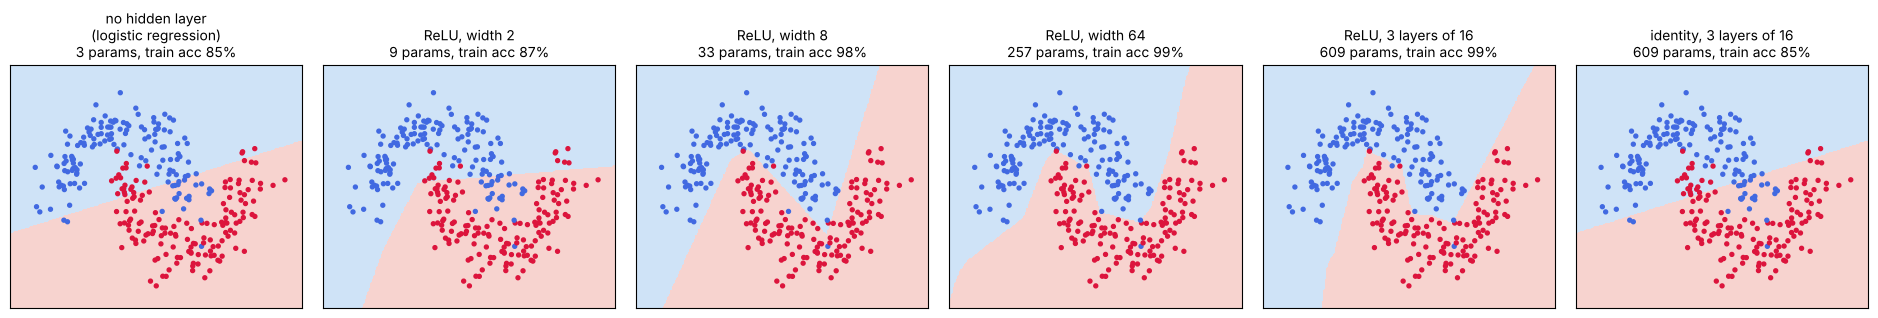

In [7]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=0)
Xm = torch.tensor(Xm, dtype=torch.float32); ym = torch.tensor(ym, dtype=torch.float32).unsqueeze(1)

torch.manual_seed(0)                                # same random biases every run
models = {
    'no hidden layer\n(logistic regression)': nn.Sequential(nn.Linear(2, 1)),
    'ReLU, width 2': mlp(2, 2, 1),
    'ReLU, width 8': mlp(2, 8, 1),
    'ReLU, width 64': mlp(2, 64, 1),
    'ReLU, 3 layers of 16': mlp(2, 16, 1, depth=3),
    'identity, 3 layers of 16': mlp(2, 16, 1, depth=3, act=nn.Identity),
}
gx = torch.linspace(-1.8, 2.8, 200); gy = torch.linspace(-1.3, 1.8, 200)
GX, GY = torch.meshgrid(gx, gy, indexing='xy')
grid2 = torch.stack([GX.ravel(), GY.ravel()], 1)

fig, ax = plt.subplots(1, len(models), figsize=(19, 3.4))
for a, (name, net) in zip(ax, models.items()):
    torch.manual_seed(0)
    for p in net.parameters():                      # same random start for every model
        if p.dim() > 1: nn.init.kaiming_uniform_(p, a=5 ** 0.5)
    fit(net, Xm, ym, nn.BCEWithLogitsLoss(), steps=3000, lr=1e-2)
    with torch.no_grad():
        acc = ((net(Xm) > 0).float() == ym).float().mean().item()
        Z = (net(grid2) > 0).float().reshape(GX.shape)
    a.contourf(GX, GY, Z, levels=[-0.5, 0.5, 1.5], colors=['#cfe3f7', '#f7d3cf'])
    a.scatter(Xm[:, 0], Xm[:, 1], c=['crimson' if v else 'royalblue' for v in ym.ravel()], s=8)
    a.set_xticks([]); a.set_yticks([])
    a.set_title(f'{name}\n{n_params(net)} params, train acc {acc:.0%}', fontsize=10)
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/moons_boundaries.png', dpi=200)
plt.show()

## 6. A dense image classifier (Fashion-MNIST)
Each 28×28 image becomes a vector of 784 numbers. Ten output units, one per class (one-vs-all, as in the slides).
`nn.CrossEntropyLoss` is the multi-class version of the logistic-regression cost (softmax + log-loss).

In [8]:
import torchvision
from torchvision import transforms

tfm = transforms.ToTensor()
train_set = torchvision.datasets.FashionMNIST('data', train=True, download=True, transform=tfm)
test_set = torchvision.datasets.FashionMNIST('data', train=False, download=True, transform=tfm)
classes = train_set.classes
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)

net = nn.Sequential(
    nn.Flatten(),             # (B, 1, 28, 28) -> (B, 784)
    nn.Linear(784, 128),      # hidden layer: 784*128 weights + 128 biases
    nn.ReLU(),
    nn.Linear(128, 10),       # one output unit (score) per class
)
print('parameters:', n_params(net))

# trace one minibatch through the model
xb, yb = next(iter(train_loader))
print('input batch :', tuple(xb.shape))
h = xb
for layer in net:
    h = layer(h)
    print(f'after {layer.__class__.__name__:8s}:', tuple(h.shape))

parameters: 101770
input batch : (64, 1, 28, 28)
after Flatten : (64, 784)
after Linear  : (64, 128)
after ReLU    : (64, 128)
after Linear  : (64, 10)


In [9]:
loss_fn = nn.CrossEntropyLoss()
if TRAIN_IMAGES:
    torch.manual_seed(0)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    for epoch in range(2):
        for xb, yb in train_loader:
            loss = loss_fn(net(xb), yb)          # forward pass + cost
            opt.zero_grad(); loss.backward(); opt.step()   # gradient + update
        print(f'epoch {epoch + 1}: last minibatch loss {loss.item():.3f}')
    torch.save(net.state_dict(), 'fashion_mlp.pt')
else:
    net.load_state_dict(torch.load('fashion_mlp.pt'))

net.eval()
correct = 0
with torch.no_grad():
    for xb, yb in test_loader:
        correct += (net(xb).argmax(1) == yb).sum().item()
acc = correct / len(test_set)
print(f'test accuracy: {acc:.1%}')

epoch 1: last minibatch loss 0.423


epoch 2: last minibatch loss 0.097


test accuracy: 85.2%


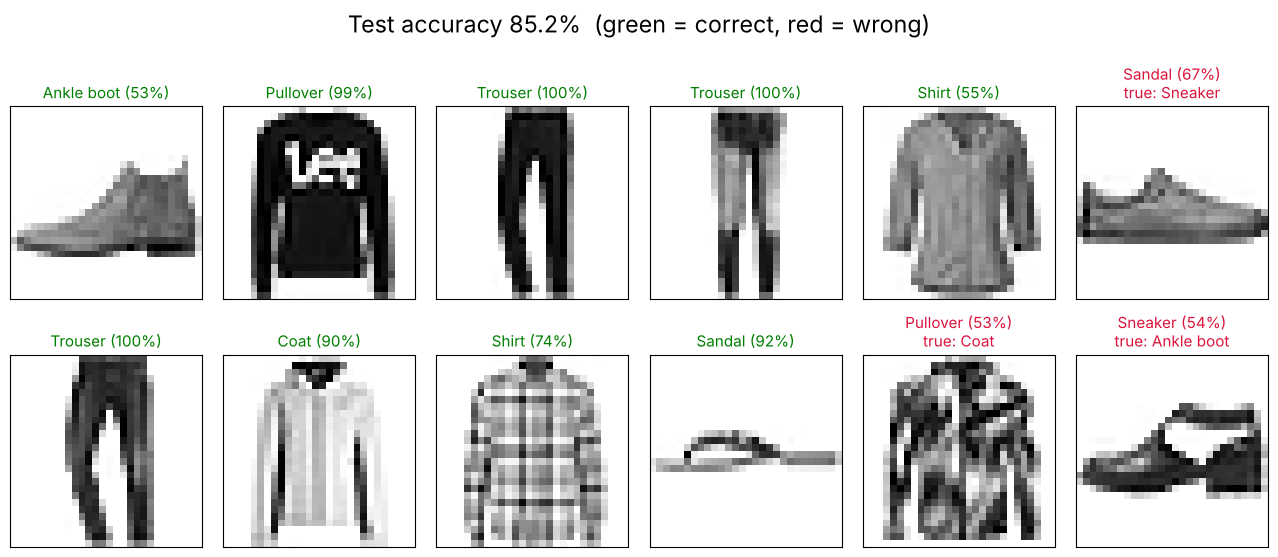

In [10]:
xb, yb = next(iter(test_loader))
with torch.no_grad():
    probs = torch.softmax(net(xb), dim=1)    # scores -> probabilities over the 10 classes
pred = probs.argmax(1)
right = (pred == yb).nonzero().ravel().tolist()
wrong = (pred != yb).nonzero().ravel().tolist()
idx = right[:5] + wrong[:1] + right[5:9] + wrong[1:3]       # mostly correct, a few mistakes
fig, ax = plt.subplots(2, 6, figsize=(13, 6))
for a, i in zip(ax.ravel(), idx):
    k = pred[i].item()
    ok = k == yb[i].item()
    a.imshow(xb[i, 0], cmap='gray_r')
    a.set_xticks([]); a.set_yticks([])
    title = f'{classes[k]} ({probs[i, k]:.0%})' + ('' if ok else f'\ntrue: {classes[yb[i].item()]}')
    a.set_title(title, fontsize=11, color='green' if ok else 'crimson')
plt.suptitle(f'Test accuracy {acc:.1%}  (green = correct, red = wrong)')
plt.tight_layout()
if SAVE_FIGS:
    plt.savefig(f'{FIG_DIR}/fashion_predictions.png', dpi=200)
plt.show()

## 7. Try it yourself
1. Section 1: what is the smallest ReLU width that fits the target well? Count its parameters.
2. Section 4: change the learning rate or the number of steps for the 2-2-1 network. Does the success rate change?
3. Section 5: replace `nn.ReLU` with `nn.Tanh` or `nn.Sigmoid`. Compare the decision boundaries.
4. Section 6: remove `nn.ReLU()` from the image classifier. What happens to the test accuracy, and why?